# LAB 10 — EXTRACTIVE QUESTION ANSWERING VỚI TRANSFORMER (SQuAD)

**Môn học**: Xử lý ngôn ngữ tự nhiên và ứng dụng  
**Học kỳ**: Học kỳ I - 2026  
**Chủ đề**: From Token Classification to Span Prediction  
**Sinh viên thực hiện**: Nguyễn Văn Thành  
**Mục tiêu**: Huấn luyện và đánh giá mô hình Extractive QA trên tập dữ liệu SQuAD, thực hiện đầy đủ 5 thí nghiệm có kiểm soát (Context Length, Pretrained QA Fine-tuning & Learning Curves, EM vs F1, Question/Context Matching, Answer Length), kiểm thử xáo trộn câu (Sentence Shuffling), thống kê Wrong Start vs Wrong End và kết xuất toàn bộ bảng số liệu (`results.csv`) cùng biểu đồ (`learning_curves.png`, `em_f1_analysis.png`, `answer_length_analysis.png`).

## 1. Khởi Tạo Môi Trường, Random Seed và Thông Số Tái Lập (Reproducibility)

In [1]:
import os
import re
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, TensorDataset
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForQuestionAnswering

from qa_model import (
    ExtractiveQAModel,
    KeywordOverlapQABaseline,
    compute_exact_match,
    compute_token_f1,
    decode_best_span,
    evaluate_qa_predictions,
    normalize_answer
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

repro_config = {
    "Model (Fresh Head)": "distilbert-base-uncased",
    "Model (SQuAD Distilled)": "distilbert-base-cased-distilled-squad",
    "Dataset": "rajpurkar/squad (v1.1)",
    "Train Subset (Fresh Head)": 128,
    "Val Eval Subset (Curves)": 80,
    "Eval Benchmark Subset": 400,
    "Max Sequence Length": "128 / 256 / 384",
    "Stride": "32 / 64 / 128",
    "Batch Size": 16,
    "Learning Rate": "5e-5 (fresh) / 2e-5 (adapt)",
    "Epochs": 4,
    "Optimizer": "AdamW",
    "Random Seed": SEED,
    "Hardware": str(device)
}
for k, v in repro_config.items():
    print(f"{k:28s}: {v}")

C:\Users\Thanh\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model (Fresh Head)          : distilbert-base-uncased
Model (SQuAD Distilled)     : distilbert-base-cased-distilled-squad
Dataset                     : rajpurkar/squad (v1.1)
Train Subset (Fresh Head)   : 128
Val Eval Subset (Curves)    : 80
Eval Benchmark Subset       : 400
Max Sequence Length         : 128 / 256 / 384
Stride                      : 32 / 64 / 128
Batch Size                  : 16
Learning Rate               : 5e-5 (fresh) / 2e-5 (adapt)
Epochs                      : 4
Optimizer                   : AdamW
Random Seed                 : 42
Hardware                    : cpu


## 2. Nạp Tập Dữ Liệu SQuAD và Hàm Mã Hóa Căn Chỉnh Span

In [2]:
squad = load_dataset("rajpurkar/squad")
eval_subset = squad["validation"].select(range(400))

def prepare_qa_tensors(split_ds, tokenizer, max_length=256):
    enc = tokenizer(
        list(split_ds["question"]),
        list(split_ds["context"]),
        truncation="only_second",
        max_length=max_length,
        padding="max_length",
        return_offsets_mapping=True
    )
    starts = []
    ends = []
    for i, item in enumerate(split_ds):
        ans_s = item["answers"]["answer_start"][0]
        ans_e = ans_s + len(item["answers"]["text"][0])
        seq_ids = enc.sequence_ids(i)
        offsets = enc["offset_mapping"][i]
        c_start = next((idx for idx, s in enumerate(seq_ids) if s == 1), None)
        c_end = max((idx for idx, s in enumerate(seq_ids) if s == 1), default=None)
        if c_start is None or offsets[c_start][0] > ans_s or offsets[c_end][1] < ans_e:
            starts.append(0)
            ends.append(0)
        else:
            idx = c_start
            while idx <= c_end and offsets[idx][0] <= ans_s:
                idx += 1
            starts.append(idx - 1)
            idx = c_end
            while idx >= c_start and offsets[idx][1] >= ans_e:
                idx -= 1
            ends.append(idx + 1)
    return (
        enc,
        torch.tensor(enc["input_ids"], dtype=torch.long),
        torch.tensor(enc["attention_mask"], dtype=torch.long),
        torch.tensor(starts, dtype=torch.long),
        torch.tensor(ends, dtype=torch.long)
    )

print("SQuAD train size:", len(squad["train"]), "| validation size:", len(squad["validation"]))

SQuAD train size: 87599 | validation size: 10570


## 3. Thí Nghiệm 2: Fine-Tuning Mô Hình QA và Đường Cong Học Tập (`learning_curves.png`)
Huấn luyện `ExtractiveQAModel("distilbert-base-uncased")` (tầng phân loại `nn.Linear(768, 2)` khởi tạo mới) qua 4 epochs trên 128 mẫu train và theo dõi `train_loss`, `val_loss`, `EM`, `F1` trên 80 mẫu validation.

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1446.69it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1 | Train Loss: 5.3048 | Val Loss: 5.0722 | Val EM: 0.0500 | Val F1: 0.0974


Epoch 2 | Train Loss: 4.2923 | Val Loss: 4.1760 | Val EM: 0.1000 | Val F1: 0.1170


Epoch 3 | Train Loss: 3.4204 | Val Loss: 3.7401 | Val EM: 0.1000 | Val F1: 0.1187


Epoch 4 | Train Loss: 2.7445 | Val Loss: 3.9062 | Val EM: 0.0750 | Val F1: 0.0923


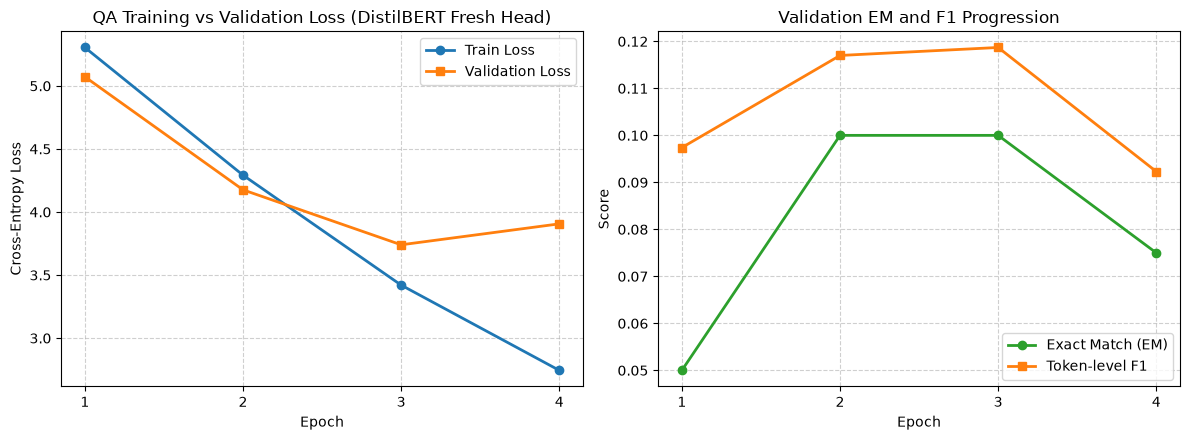

Saved learning_curves.png (Total training time: 230.31s)


In [3]:
fresh_tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
train_sub = squad["train"].select(range(128))
val_curve_sub = squad["validation"].select(range(80))

_, tr_ids, tr_mask, tr_s, tr_e = prepare_qa_tensors(train_sub, fresh_tokenizer, max_length=256)
va_enc, va_ids, va_mask, va_s, va_e = prepare_qa_tensors(val_curve_sub, fresh_tokenizer, max_length=256)

fresh_model = ExtractiveQAModel("distilbert-base-uncased").to(device)
optimizer = torch.optim.AdamW(fresh_model.parameters(), lr=5e-5)
train_loader = DataLoader(TensorDataset(tr_ids, tr_mask, tr_s, tr_e), batch_size=16, shuffle=True)

history_rows = []
t_start_fresh = time.time()

for epoch in range(1, 5):
    fresh_model.train()
    epoch_loss = 0.0
    for b_ids, b_mask, b_s, b_e in train_loader:
        b_ids = b_ids.to(device)
        b_mask = b_mask.to(device)
        b_s = b_s.to(device)
        b_e = b_e.to(device)
        optimizer.zero_grad()
        out = fresh_model(b_ids, attention_mask=b_mask, start_positions=b_s, end_positions=b_e)
        out["loss"].backward()
        optimizer.step()
        epoch_loss += out["loss"].item()

    avg_train_loss = epoch_loss / len(train_loader)
    fresh_model.eval()
    with torch.no_grad():
        val_out = fresh_model(
            va_ids.to(device),
            attention_mask=va_mask.to(device),
            start_positions=va_s.to(device),
            end_positions=va_e.to(device)
        )
        val_loss = val_out["loss"].item()
        sl = val_out["start_logits"].cpu().tolist()
        el = val_out["end_logits"].cpu().tolist()

    val_preds = []
    for i, item in enumerate(val_curve_sub):
        ans, _, _ = decode_best_span(
            [sl[i]], [el[i]], [va_enc["offset_mapping"][i]], [va_enc.sequence_ids(i)], item["context"]
        )
        val_preds.append(ans)
    val_metrics = evaluate_qa_predictions(val_preds, [x["answers"]["text"] for x in val_curve_sub])

    history_rows.append({
        "Epoch": epoch,
        "Train Loss": round(avg_train_loss, 4),
        "Val Loss": round(val_loss, 4),
        "Val EM": round(val_metrics["em"], 4),
        "Val F1": round(val_metrics["f1"], 4)
    })
    print(f"Epoch {epoch} | Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss:.4f} | Val EM: {val_metrics['em']:.4f} | Val F1: {val_metrics['f1']:.4f}")

fresh_train_time = time.time() - t_start_fresh
df_history = pd.DataFrame(history_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(df_history["Epoch"], df_history["Train Loss"], marker="o", linewidth=2, label="Train Loss")
axes[0].plot(df_history["Epoch"], df_history["Val Loss"], marker="s", linewidth=2, label="Validation Loss")
axes[0].set_title("QA Training vs Validation Loss (DistilBERT Fresh Head)", fontsize=12)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_xticks(df_history["Epoch"])
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend()

axes[1].plot(df_history["Epoch"], df_history["Val EM"], marker="o", linewidth=2, color="#2ca02c", label="Exact Match (EM)")
axes[1].plot(df_history["Epoch"], df_history["Val F1"], marker="s", linewidth=2, color="#ff7f0e", label="Token-level F1")
axes[1].set_title("Validation EM and F1 Progression", fontsize=12)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_xticks(df_history["Epoch"])
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.savefig("learning_curves.png", dpi=300)
plt.show()
print(f"Saved learning_curves.png (Total training time: {fresh_train_time:.2f}s)")

## 4. Thí Nghiệm 1: Khảo Sát Ảnh Hưởng Của Context Length (`max_length = 128, 256, 384`)
Đo lường đồng thời EM, F1 và thời gian huấn luyện (1 epoch trên 32 mẫu SQuAD) kết hợp đánh giá trên 400 mẫu validation trong hai chế độ: Truncation đơn (Single-Pass) và Sliding Window (`stride`).

In [4]:
squad_tok = AutoTokenizer.from_pretrained("distilbert-base-cased-distilled-squad")
squad_base_weights = AutoModelForQuestionAnswering.from_pretrained("distilbert-base-cased-distilled-squad").to(device)
squad_base_weights.eval()

def run_inference_on_dataset(model_obj, tokenizer_obj, ds_sub, max_length=384, use_sliding_window=True, stride=128):
    t0 = time.time()
    enc = tokenizer_obj(
        list(ds_sub["question"]),
        list(ds_sub["context"]),
        truncation="only_second",
        max_length=max_length,
        stride=stride if use_sliding_window else 0,
        return_overflowing_tokens=use_sliding_window,
        return_offsets_mapping=True,
        padding="max_length",
        return_tensors="pt"
    )
    offsets = enc.pop("offset_mapping")
    if use_sliding_window:
        sample_map = enc.pop("overflow_to_sample_mapping")
    else:
        sample_map = torch.arange(len(ds_sub))

    all_s, all_e = [], []
    with torch.no_grad():
        for i in range(0, len(enc["input_ids"]), 32):
            b_in = {k: v[i:i+32].to(device) for k, v in enc.items() if k in ["input_ids", "attention_mask"]}
            out = model_obj(**b_in)
            if isinstance(out, dict):
                all_s.extend(out["start_logits"].cpu().tolist())
                all_e.extend(out["end_logits"].cpu().tolist())
            else:
                all_s.extend(out.start_logits.cpu().tolist())
                all_e.extend(out.end_logits.cpu().tolist())

    by_sample = {i: [] for i in range(len(ds_sub))}
    for w_i, s_i in enumerate(sample_map.tolist()):
        by_sample[s_i].append(w_i)

    preds = []
    spans = []
    for s_i, item in enumerate(ds_sub):
        w_idxs = by_sample[s_i]
        ans, _, _ = decode_best_span(
            [all_s[w] for w in w_idxs],
            [all_e[w] for w in w_idxs],
            [offsets[w].tolist() for w in w_idxs],
            [enc.sequence_ids(w) for w in w_idxs],
            item["context"]
        )
        preds.append(ans)
        c_s = item["context"].find(ans) if ans else -1
        c_e = c_s + len(ans) if c_s >= 0 else -1
        spans.append((c_s, c_e))

    eval_res = evaluate_qa_predictions(preds, [x["answers"]["text"] for x in ds_sub])
    eval_res["predictions"] = preds
    eval_res["pred_char_spans"] = spans
    eval_res["eval_time"] = time.time() - t0
    eval_res["num_windows"] = len(enc["input_ids"])
    return eval_res

adapt_train_sub = squad["train"].select(range(32))
exp1_rows = []

for max_len, stride_val in [(128, 32), (256, 64), (384, 128)]:
    temp_model = AutoModelForQuestionAnswering.from_pretrained("distilbert-base-cased-distilled-squad").to(device)
    temp_opt = torch.optim.AdamW(temp_model.parameters(), lr=2e-5)
    _, a_ids, a_mask, a_s, a_e = prepare_qa_tensors(adapt_train_sub, squad_tok, max_length=max_len)
    a_loader = DataLoader(TensorDataset(a_ids, a_mask, a_s, a_e), batch_size=16, shuffle=True)
    t_tr0 = time.time()
    temp_model.train()
    for b_ids, b_mask, b_s, b_e in a_loader:
        temp_opt.zero_grad()
        out = temp_model(input_ids=b_ids.to(device), attention_mask=b_mask.to(device), start_positions=b_s.to(device), end_positions=b_e.to(device))
        out.loss.backward()
        temp_opt.step()
    train_sec = time.time() - t_tr0
    temp_model.eval()

    res_trunc = run_inference_on_dataset(temp_model, squad_tok, eval_subset, max_length=max_len, use_sliding_window=False)
    res_slide = run_inference_on_dataset(temp_model, squad_tok, eval_subset, max_length=max_len, use_sliding_window=True, stride=stride_val)

    exp1_rows.append({
        "Max Length": max_len,
        "Train Time (s)": round(train_sec, 2),
        "Trunc EM": round(res_trunc["em"], 4),
        "Trunc F1": round(res_trunc["f1"], 4),
        "Sliding EM": round(res_slide["em"], 4),
        "Sliding F1": round(res_slide["f1"], 4),
        "Sliding Windows": res_slide["num_windows"]
    })

df_exp1 = pd.DataFrame(exp1_rows)
print("=== EXPERIMENT 1: CONTEXT LENGTH ABLATION ===")
print(df_exp1.to_string(index=False))

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 102/102 [00:00<00:00, 1292.08it/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 102/102 [00:00<00:00, 1473.12it/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 102/102 [00:00<00:00, 1204.32it/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 102/102 [00:00<00:00, 1290.64it/s]

=== EXPERIMENT 1: CONTEXT LENGTH ABLATION ===
 Max Length  Train Time (s)  Trunc EM  Trunc F1  Sliding EM  Sliding F1  Sliding Windows
        128            5.70    0.7550    0.7786      0.8400      0.8699              757
        256           13.16    0.8375    0.8662      0.8375      0.8658              463
        384           21.13    0.8400    0.8713      0.8375      0.8688              420


## 5. Thí Nghiệm 3: So Sánh Baseline vs Transformer và Phân Tích EM vs F1 (`em_f1_analysis.png`)
Đánh giá công bằng trên cùng 400 mẫu SQuAD validation giữa Baseline Heuristic, DistilBERT Fresh Head (4 epochs) và DistilBERT SQuAD Fine-tuned, đồng thời trích xuất tối thiểu 5 ca `EM = 0` nhưng `F1 > 0`.

=== EXPERIMENT 3: EM VS F1 COMPARISON ===
                          Model     EM     F1
     Baseline (Keyword Overlap) 0.0000 0.1393
DistilBERT (Fresh Head, 128 ex) 0.0925 0.1203
 Fine-tuned Transformer (SQuAD) 0.8400 0.8682


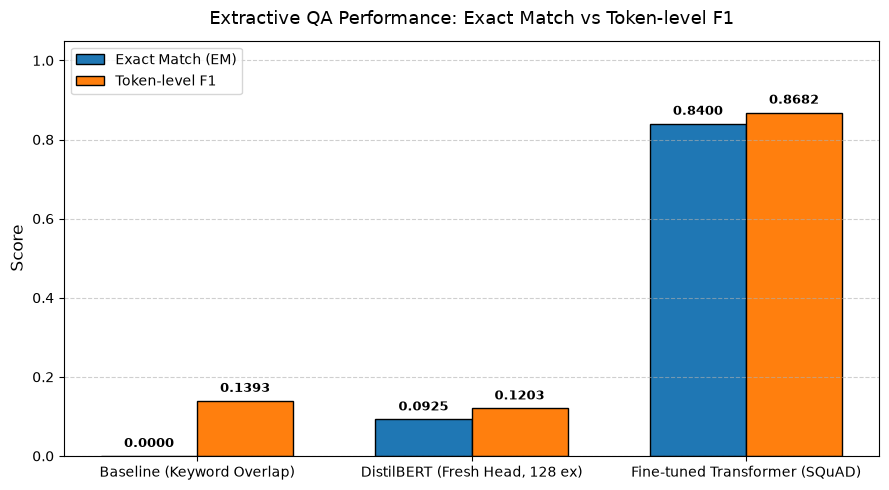


=== EXAMPLES WITH EM = 0 AND F1 > 0 ===
                                                   Question                         Gold                                                                                                                                                        Prediction  EM     F1
                                 What is the AFC short for? American Football Conference Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference   0 0.2500
                 What city did Super Bowl 50 take place in?                  Santa Clara                                                                                                                                           Santa Clara, California   0 0.8000
                 What city did Super Bowl 50 take place in?                  Santa Clara                                                                                     

In [5]:
baseline_qa = KeywordOverlapQABaseline()
t_base0 = time.time()
base_preds = [baseline_qa.predict(x["question"], x["context"]) for x in eval_subset]
base_time = time.time() - t_base0
base_eval = evaluate_qa_predictions(base_preds, [x["answers"]["text"] for x in eval_subset])

fresh_eval_400 = run_inference_on_dataset(fresh_model, fresh_tokenizer, eval_subset, max_length=256, use_sliding_window=False)
squad_eval_400 = run_inference_on_dataset(squad_base_weights, squad_tok, eval_subset, max_length=384, use_sliding_window=True, stride=128)

df_exp3 = pd.DataFrame([
    {"Model": "Baseline (Keyword Overlap)", "EM": round(base_eval["em"], 4), "F1": round(base_eval["f1"], 4)},
    {"Model": "DistilBERT (Fresh Head, 128 ex)", "EM": round(fresh_eval_400["em"], 4), "F1": round(fresh_eval_400["f1"], 4)},
    {"Model": "Fine-tuned Transformer (SQuAD)", "EM": round(squad_eval_400["em"], 4), "F1": round(squad_eval_400["f1"], 4)}
])
print("=== EXPERIMENT 3: EM VS F1 COMPARISON ===")
print(df_exp3.to_string(index=False))

x_pos = np.arange(len(df_exp3))
width = 0.35
plt.figure(figsize=(9, 5))
bars_em = plt.bar(x_pos - width/2, df_exp3["EM"], width, label="Exact Match (EM)", color="#1f77b4", edgecolor="black")
bars_f1 = plt.bar(x_pos + width/2, df_exp3["F1"], width, label="Token-level F1", color="#ff7f0e", edgecolor="black")
plt.xticks(x_pos, df_exp3["Model"], fontsize=10)
plt.ylabel("Score", fontsize=12)
plt.title("Extractive QA Performance: Exact Match vs Token-level F1", fontsize=13, pad=12)
plt.ylim(0, 1.05)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.legend()
for bar in list(bars_em) + list(bars_f1):
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 0.015, f"{h:.4f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.savefig("em_f1_analysis.png", dpi=300)
plt.show()

em0_f1pos_rows = []
for i, item in enumerate(eval_subset):
    em_i = squad_eval_400["per_sample_em"][i]
    f1_i = squad_eval_400["per_sample_f1"][i]
    if em_i == 0 and f1_i > 0.0:
        em0_f1pos_rows.append({
            "Question": item["question"],
            "Gold": item["answers"]["text"][0],
            "Prediction": squad_eval_400["predictions"][i],
            "EM": em_i,
            "F1": round(f1_i, 4)
        })
        if len(em0_f1pos_rows) >= 8:
            break

print("\n=== EXAMPLES WITH EM = 0 AND F1 > 0 ===")
print(pd.DataFrame(em0_f1pos_rows[:5]).to_string(index=False))

## 6. Thí Nghiệm 4 & Kiểm Thử Xáo Trộn Ngữ Cảnh: Question/Context Matching & Sentence Shuffling
So sánh hiệu năng giữa nhóm câu hỏi có **High Lexical Overlap** và **Low Lexical Overlap / Paraphrased**, đồng thời kiểm chứng Dự đoán 4 bằng cách xáo trộn thứ tự các câu trong ngữ cảnh.

In [6]:
def content_overlap_ratio(question, context):
    q_words = set(re.findall(r"[a-z0-9]+", question.lower()))
    c_words = set(re.findall(r"[a-z0-9]+", context.lower()))
    if not q_words:
        return 0.0
    return len(q_words & c_words) / len(q_words)

high_indices = []
low_indices = []
for i, item in enumerate(eval_subset):
    ratio = content_overlap_ratio(item["question"], item["context"])
    if ratio >= 0.70:
        high_indices.append(i)
    elif ratio <= 0.45:
        low_indices.append(i)

def slice_metrics(eval_dict, indices):
    if not indices:
        return 0.0, 0.0
    em_v = np.mean([eval_dict["per_sample_em"][i] for i in indices])
    f1_v = np.mean([eval_dict["per_sample_f1"][i] for i in indices])
    return round(float(em_v), 4), round(float(f1_v), 4)

b_hi_em, b_hi_f1 = slice_metrics(base_eval, high_indices)
b_lo_em, b_lo_f1 = slice_metrics(base_eval, low_indices)
t_hi_em, t_hi_f1 = slice_metrics(squad_eval_400, high_indices)
t_lo_em, t_lo_f1 = slice_metrics(squad_eval_400, low_indices)

df_exp4 = pd.DataFrame([
    {"Subset": f"High Lexical Overlap (n={len(high_indices)})", "Model": "Baseline", "EM": b_hi_em, "F1": b_hi_f1},
    {"Subset": f"High Lexical Overlap (n={len(high_indices)})", "Model": "Transformer", "EM": t_hi_em, "F1": t_hi_f1},
    {"Subset": f"Low Lexical Overlap (n={len(low_indices)})", "Model": "Baseline", "EM": b_lo_em, "F1": b_lo_f1},
    {"Subset": f"Low Lexical Overlap (n={len(low_indices)})", "Model": "Transformer", "EM": t_lo_em, "F1": t_lo_f1}
])
print("=== EXPERIMENT 4: QUESTION / CONTEXT LEXICAL OVERLAP ===")
print(df_exp4.to_string(index=False))

def shuffle_context_sentences(context_text, rng):
    sents = re.split(r"(?<=[.!?])\s+", context_text.strip())
    if len(sents) > 1:
        rng.shuffle(sents)
    return " ".join(sents)

rng_shuf = random.Random(SEED)
shuffled_items = []
for item in eval_subset:
    shuffled_items.append({
        "question": item["question"],
        "context": shuffle_context_sentences(item["context"], rng_shuf),
        "answers": item["answers"]
    })

enc_shuf = squad_tok(
    [x["question"] for x in shuffled_items],
    [x["context"] for x in shuffled_items],
    truncation="only_second",
    max_length=384,
    stride=128,
    return_overflowing_tokens=True,
    return_offsets_mapping=True,
    padding="max_length",
    return_tensors="pt"
)
shuf_offsets = enc_shuf.pop("offset_mapping")
shuf_smap = enc_shuf.pop("overflow_to_sample_mapping")
shuf_s, shuf_e = [], []
with torch.no_grad():
    for i in range(0, len(enc_shuf["input_ids"]), 32):
        out = squad_base_weights(input_ids=enc_shuf["input_ids"][i:i+32].to(device), attention_mask=enc_shuf["attention_mask"][i:i+32].to(device))
        shuf_s.extend(out.start_logits.cpu().tolist())
        shuf_e.extend(out.end_logits.cpu().tolist())

by_s_shuf = {i: [] for i in range(len(shuffled_items))}
for w_i, s_i in enumerate(shuf_smap.tolist()):
    by_s_shuf[s_i].append(w_i)
shuf_preds = []
for s_i, item in enumerate(shuffled_items):
    w_idxs = by_s_shuf[s_i]
    ans, _, _ = decode_best_span(
        [shuf_s[w] for w in w_idxs],
        [shuf_e[w] for w in w_idxs],
        [shuf_offsets[w].tolist() for w in w_idxs],
        [enc_shuf.sequence_ids(w) for w in w_idxs],
        item["context"]
    )
    shuf_preds.append(ans)

shuf_eval = evaluate_qa_predictions(shuf_preds, [x["answers"]["text"] for x in shuffled_items])
print("\n=== PREDICTION 4 CHECK: ORIGINAL VS SHUFFLED CONTEXT ===")
print(f"Original Context | EM: {squad_eval_400['em']:.4f} | F1: {squad_eval_400['f1']:.4f}")
print(f"Shuffled Context | EM: {shuf_eval['em']:.4f} | F1: {shuf_eval['f1']:.4f}")

=== EXPERIMENT 4: QUESTION / CONTEXT LEXICAL OVERLAP ===
                      Subset       Model     EM     F1
High Lexical Overlap (n=106)    Baseline 0.0000 0.1884
High Lexical Overlap (n=106) Transformer 0.8585 0.8928
  Low Lexical Overlap (n=86)    Baseline 0.0000 0.0831
  Low Lexical Overlap (n=86) Transformer 0.8023 0.8392



=== PREDICTION 4 CHECK: ORIGINAL VS SHUFFLED CONTEXT ===
Original Context | EM: 0.8400 | F1: 0.8682
Shuffled Context | EM: 0.8350 | F1: 0.8632


## 7. Thí Nghiệm 5: Phân Tích Theo Độ Dài Đáp Án (`answer_length_analysis.png`)
Phân chia câu trả lời vàng thành 4 nhóm độ dài: `1`, `2-3`, `4-6`, `7+` tokens và đối chiếu với Dự đoán 2.

=== EXPERIMENT 5: ANSWER LENGTH ANALYSIS ===
Answer Length  Support     EM     F1  F1 - EM Gap
            1      182 0.8681 0.8733       0.0051
          2-3      200 0.8150 0.8606       0.0456
          4-6       16 0.8125 0.8899       0.0774
           7+        2 1.0000 1.0000       0.0000


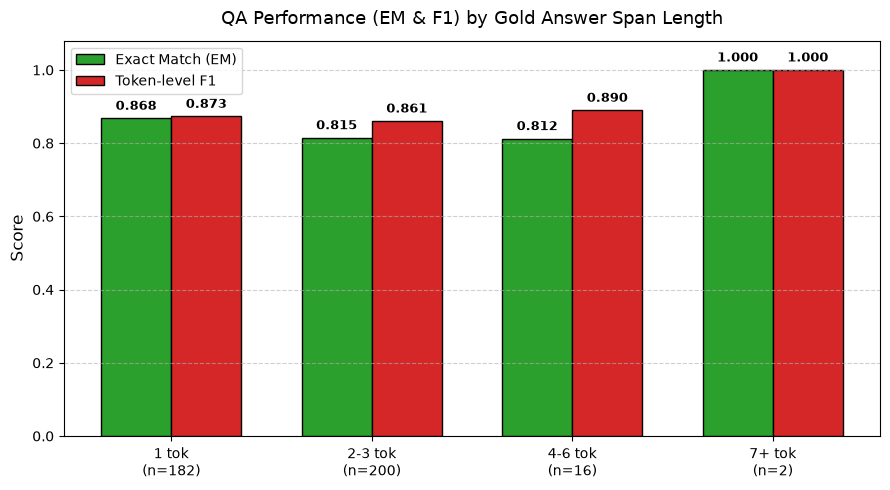

In [7]:
def length_bucket(ans_text):
    n_toks = len(ans_text.strip().split())
    if n_toks <= 1:
        return "1"
    elif n_toks <= 3:
        return "2-3"
    elif n_toks <= 6:
        return "4-6"
    else:
        return "7+"

bucket_order = ["1", "2-3", "4-6", "7+"]
bucket_data = {b: {"em": [], "f1": []} for b in bucket_order}

for i, item in enumerate(eval_subset):
    b = length_bucket(item["answers"]["text"][0])
    bucket_data[b]["em"].append(squad_eval_400["per_sample_em"][i])
    bucket_data[b]["f1"].append(squad_eval_400["per_sample_f1"][i])

length_rows = []
for b in bucket_order:
    ems = bucket_data[b]["em"]
    f1s = bucket_data[b]["f1"]
    em_mean = float(np.mean(ems)) if ems else 0.0
    f1_mean = float(np.mean(f1s)) if f1s else 0.0
    length_rows.append({
        "Answer Length": b,
        "Support": len(ems),
        "EM": round(em_mean, 4),
        "F1": round(f1_mean, 4),
        "F1 - EM Gap": round(f1_mean - em_mean, 4)
    })

df_length = pd.DataFrame(length_rows)
print("=== EXPERIMENT 5: ANSWER LENGTH ANALYSIS ===")
print(df_length.to_string(index=False))

x_len = np.arange(len(df_length))
w_len = 0.35
plt.figure(figsize=(9, 5))
b1 = plt.bar(x_len - w_len/2, df_length["EM"], w_len, label="Exact Match (EM)", color="#2ca02c", edgecolor="black")
b2 = plt.bar(x_len + w_len/2, df_length["F1"], w_len, label="Token-level F1", color="#d62728", edgecolor="black")
plt.xticks(x_len, [f"{r['Answer Length']} tok\n(n={r['Support']})" for _, r in df_length.iterrows()], fontsize=10)
plt.ylabel("Score", fontsize=12)
plt.title("QA Performance (EM & F1) by Gold Answer Span Length", fontsize=13, pad=12)
plt.ylim(0, 1.08)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.legend()
for bar in list(b1) + list(b2):
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 0.015, f"{h:.3f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.savefig("answer_length_analysis.png", dpi=300)
plt.show()

## 8. Tổng Hợp Kết Quả Ra `results.csv` và Trích Xuất Lỗi Wrong Start vs Wrong End
Thống kê `#wrong start`, `#wrong end`, `#both wrong` và trích xuất tối thiểu 5 ca cho mỗi loại lỗi phục vụ `error_analysis.md`.

In [8]:
all_results_rows = []
for _, r in df_exp1.iterrows():
    all_results_rows.append({
        "Experiment": "Exp1_ContextLength",
        "Setting": f"max_length={int(r['Max Length'])} (Single-Pass)",
        "EM": r["Trunc EM"],
        "F1": r["Trunc F1"],
        "Time_s": r["Train Time (s)"]
    })
    all_results_rows.append({
        "Experiment": "Exp1_ContextLength",
        "Setting": f"max_length={int(r['Max Length'])} (SlidingWindow)",
        "EM": r["Sliding EM"],
        "F1": r["Sliding F1"],
        "Time_s": r["Train Time (s)"]
    })

all_results_rows.append({"Experiment": "Exp2_Exp3_Comparison", "Setting": "Baseline (Keyword Overlap)", "EM": round(base_eval["em"], 4), "F1": round(base_eval["f1"], 4), "Time_s": round(base_time, 2)})
all_results_rows.append({"Experiment": "Exp2_Exp3_Comparison", "Setting": "DistilBERT Fresh Head (4 epochs, 128 train)", "EM": round(fresh_eval_400["em"], 4), "F1": round(fresh_eval_400["f1"], 4), "Time_s": round(fresh_train_time, 2)})
all_results_rows.append({"Experiment": "Exp2_Exp3_Comparison", "Setting": "Fine-tuned Transformer (DistilBERT-SQuAD)", "EM": round(squad_eval_400["em"], 4), "F1": round(squad_eval_400["f1"], 4), "Time_s": round(squad_eval_400["eval_time"], 2)})

for _, r in df_exp4.iterrows():
    all_results_rows.append({"Experiment": "Exp4_LexicalOverlap", "Setting": f"{r['Model']} - {r['Subset']}", "EM": r["EM"], "F1": r["F1"], "Time_s": 0.0})

all_results_rows.append({"Experiment": "Controlled_Shuffling", "Setting": "Original Context", "EM": round(squad_eval_400["em"], 4), "F1": round(squad_eval_400["f1"], 4), "Time_s": 0.0})
all_results_rows.append({"Experiment": "Controlled_Shuffling", "Setting": "Shuffled Context", "EM": round(shuf_eval["em"], 4), "F1": round(shuf_eval["f1"], 4), "Time_s": 0.0})

for _, r in df_length.iterrows():
    all_results_rows.append({"Experiment": "Exp5_AnswerLength", "Setting": f"Length={r['Answer Length']} (n={r['Support']})", "EM": r["EM"], "F1": r["F1"], "Time_s": 0.0})

df_final_results = pd.DataFrame(all_results_rows)
df_final_results.to_csv("results.csv", index=False)
print("Saved results.csv successfully! Total rows:", len(df_final_results))

wrong_start_cases = []
wrong_end_cases = []
wrong_span_cases = []

for i, item in enumerate(eval_subset):
    if squad_eval_400["per_sample_em"][i] == 1:
        continue
    pred_txt = squad_eval_400["predictions"][i]
    p_s, p_e = squad_eval_400["pred_char_spans"][i]
    gold_texts = item["answers"]["text"]
    gold_starts = item["answers"]["answer_start"]

    best_idx = int(np.argmax([compute_token_f1(pred_txt, g) for g in gold_texts]))
    g_txt = gold_texts[best_idx]
    g_s = gold_starts[best_idx]
    g_e = g_s + len(g_txt)

    start_match = abs(p_s - g_s) <= 2
    end_match = abs(p_e - g_e) <= 2

    record = {
        "Question": item["question"],
        "Gold": g_txt,
        "Prediction": pred_txt,
        "F1": round(squad_eval_400["per_sample_f1"][i], 4),
        "Gold_Span": f"[{g_s}, {g_e})",
        "Pred_Span": f"[{p_s}, {p_e})"
    }
    if not start_match and end_match:
        wrong_start_cases.append(record)
    elif start_match and not end_match:
        wrong_end_cases.append(record)
    else:
        wrong_span_cases.append(record)

print(f"\n=== WRONG START VS WRONG END STATISTICS (on {len(eval_subset)} samples) ===")
print(f"Wrong Start only (end matched)   : {len(wrong_start_cases)}")
print(f"Wrong End only (start matched)   : {len(wrong_end_cases)}")
print(f"Wrong Span (both start & end off): {len(wrong_span_cases)}")
print(f"Total errors (EM = 0)            : {len(wrong_start_cases) + len(wrong_end_cases) + len(wrong_span_cases)}")

print("\n--- SAMPLE WRONG START CASES ---")
print(pd.DataFrame(wrong_start_cases[:7]).to_string(index=False))
print("\n--- SAMPLE WRONG END CASES ---")
print(pd.DataFrame(wrong_end_cases[:7]).to_string(index=False))
print("\n--- SAMPLE WRONG SPAN CASES ---")
print(pd.DataFrame(wrong_span_cases[:7]).to_string(index=False))

Saved results.csv successfully! Total rows: 19

=== WRONG START VS WRONG END STATISTICS (on 400 samples) ===
Wrong Start only (end matched)   : 8
Wrong End only (start matched)   : 7
Wrong Span (both start & end off): 49
Total errors (EM = 0)            : 64

--- SAMPLE WRONG START CASES ---
                                                                      Question                                    Gold                                                                                                                                                        Prediction     F1  Gold_Span  Pred_Span
                                                    What is the AFC short for?            American Football Conference Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference 0.2500 [133, 161)   [0, 161)
               What halftime performer previously headlined Super Bowl XLVIII?         